# Notebook 4 — End-to-end demo: fusion, hourly monitoring, re-imaging and grounded reports

**What this notebook does**
1. Loads the trained artifacts of Notebooks 1–3 (no retraining).
2. Builds **one simulated composite patient** from three independent datasets (WiDS background + PhysioNet vitals + RSNA X-rays). These records belong to different real people; treating them as one patient is a deliberate prototype assumption.
3. Runs hourly monitoring:
   - **t = 0** (end of the 5-hour warm-up): `p_base` once, first `p_ts`, first X-ray → composite index → **Report 1**.
   - **Every hour**: slide the 12-hour window → new `p_ts` → composite updated; imaging held constant.
   - **Trigger** (rule from Notebook 2: sustained high `p_ts` or rapid rise, 12-hour cooldown) → simulated follow-up X-ray → **new report**.
   - **Stops** when the composite stays high (critical), the patient stays low (improving), or `MAX_HOURS` is reached.
4. Each report: patient data, SHAP bar chart, trend chart, X-ray with boxes and zones, retrieved reference notes, and a MedGemma summary written **only** from a structured JSON.

**Composite index (not a mortality probability)**
`z = logit(p_base) + clip(α·Δ_ts, ±2) + clip(β·Δ_img, ±2)`, with `Δ = logit(p) − logit(that model's training base rate)`, `α, β` = Brier skill scores from Notebooks 2–3.

**Inputs (Add Input):** the saved outputs of Notebooks 1, 2, 3 · `mtsamples.csv` (Kaggle dataset *Medical Transcriptions*) · Secret `HF_TOKEN` (MedGemma terms accepted on Hugging Face).
**Settings:** GPU T4, Internet ON (MedGemma download, ~9 GB, first run only).

## 1. Setup and configuration

In [16]:
import os, sys, glob, json, re, shutil, zipfile, subprocess, warnings, time, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 120)

# ---------------- demo configuration ----------------
SEED               = 7
SCENARIO           = "improving"   # "deteriorating" (follow-up images get worse) or "improving"
MAX_HOURS          = 144               # hard stop for the demo
CAP                = 2.0               # max |contribution| of each adjustment, in log-odds
CRITICAL_COMPOSITE = 0.50              # stop: composite >= this ...
CRITICAL_HOURS     = 6                 # ... for this many consecutive hours
IMPROVE_MIN_HOUR   = 24                # "improving" stop only considered after this ICU hour
IMPROVE_HOURS      = 12                # p_ts below its base rate AND composite below p_base for this many hours
INITIAL_IMAGE_TIER = "moderate"        # tier of the t=0 X-ray in the demo pool
MAX_REIMAGINGS     = 4                 # after this many follow-up images, further triggers are logged as alerts only
FIXED = {"ts_record": None, "wids_encounter": None, "image_t0": None}   # set IDs to reproduce a specific case
LOG_EVERY          = 6                 # print a one-line status every N hours

LLM_MODE   = os.environ.get("NB4_LLM", "llm")        # "llm" or "template" (no LLM)
LLM_ID     = "Qwen/Qwen3-4B-Instruct-2507"           # or "unsloth/medgemma-1.5-4b-it" (then use ~1500 tokens)
LLM_MAX_NEW_TOKENS = 600

INPUT_ROOT = os.environ.get("NB4_INPUT", "/kaggle/input")
WORK_DIR   = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath(".")
RUN_DIR    = os.path.join(WORK_DIR, "demo_run"); UTIL_DIR = os.path.join(WORK_DIR, "medagent_utils")
os.makedirs(RUN_DIR, exist_ok=True); os.makedirs(UTIL_DIR, exist_ok=True)

def pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

pip("fairlearn")                                   # needed to unpickle Notebook 1's equalized-odds post-processor
if LLM_MODE != "template":
    pip("-U", "transformers>=4.51", "accelerate", "bitsandbytes")

rng = np.random.default_rng(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| LLM mode:", LLM_MODE, "| scenario:", SCENARIO, "| max hours:", MAX_HOURS)

device: cuda | LLM mode: llm | scenario: improving | max hours: 144


## 2. Locate and load the artifacts of Notebooks 1–3

In [17]:
def find_artifacts(name, marker):
    hits = glob.glob(os.path.join(INPUT_ROOT, "**", name, marker), recursive=True)
    if hits:
        return os.path.dirname(hits[0])
    zips = glob.glob(os.path.join(INPUT_ROOT, "**", f"{name}.zip"), recursive=True)
    if zips:
        dst = os.path.join("/tmp" if os.path.isdir("/tmp") else WORK_DIR, name)
        if not os.path.exists(os.path.join(dst, marker)):
            with zipfile.ZipFile(zips[0]) as z:
                z.extractall(dst)
        return dst
    raise FileNotFoundError(f"{name}/{marker} not found under {INPUT_ROOT}. Add the saved output of that notebook as an input.")

XGB_DIR = find_artifacts("artifacts_xgboost", "xgb_inference.py")
TS_DIR  = find_artifacts("artifacts_transformer", "ts_inference.py")
IMG_DIR = find_artifacts("artifacts_imaging", "img_inference.py")
MTS_CSV = (glob.glob(os.path.join(INPUT_ROOT, "**", "mtsamples.csv"), recursive=True) or [None])[0]
for k, v in [("xgboost", XGB_DIR), ("transformer", TS_DIR), ("imaging", IMG_DIR), ("mtsamples", MTS_CSV)]:
    print(f"{k:12s} {v}")
assert MTS_CSV, "mtsamples.csv not found - add the 'Medical Transcriptions' dataset."

sys.dont_write_bytecode = True
for d in (XGB_DIR, TS_DIR, IMG_DIR, UTIL_DIR):
    if d not in sys.path:
        sys.path.insert(0, d)

from xgb_inference import BaselineRiskModel
from ts_inference import VitalsRiskModel
from img_inference import ImagingRiskModel
base = BaselineRiskModel(XGB_DIR)
ts   = VitalsRiskModel(TS_DIR)
im   = ImagingRiskModel(IMG_DIR)

TRIG = dict(ts.trigger_cfg)
if "rise_floor" not in TRIG:
    print("WARNING: Notebook 2 output uses the OLD trigger rule (no rise_floor / patient-level tuning). "
          "Attach the latest saved version of Notebook 2. Using rise_floor = training base rate for now.")
    TRIG["rise_floor"] = ts.base_rate
TRIG.setdefault("initial_image_hour", ts.cfg["warmup"])

weights = pd.DataFrame({
    "model": ["baseline (XGBoost)", "vitals (Transformer)", "imaging (Faster R-CNN)"],
    "role": ["anchor, computed once", "hourly adjustment", "adjustment, held until next image"],
    "weight in fusion": ["1 (not weighted)", f"α = {ts.alpha:.3f}", f"β = {im.beta:.3f}"],
    "training base rate": [base.base_rate, ts.base_rate, im.base_rate],
    "test Brier skill score": [base.bss, ts.alpha, im.beta]})
display(weights.round(4))
print("trigger rule:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in TRIG.items() if k in
      ["theta", "k_consecutive", "rise_hours", "rise_delta", "rise_floor", "cooldown_hours", "initial_image_hour"]})

xgboost      /kaggle/input/notebooks/anarvaaa/notebook1-medical/artifacts_xgboost
transformer  /kaggle/input/notebooks/anarvaaa/notebook2-medical/artifacts_transformer
imaging      /kaggle/input/notebooks/anarvaaa/notebook3-medical/artifacts_imaging
mtsamples    /kaggle/input/datasets/tboyle10/medicaltranscriptions/mtsamples.csv


,model,role,weight in fusion,training base rate,test Brier skill score
0,baseline (XGBoost),"anchor, computed once",1 (not weighted),0.0863,0.0576
1,vitals (Transformer),hourly adjustment,α = 0.201,0.1423,0.2009
2,imaging (Faster R-CNN),"adjustment, held until next image",β = 0.386,0.2253,0.3863


trigger rule: {'theta': 0.2747, 'k_consecutive': 3, 'rise_hours': 4, 'rise_delta': 0.184, 'rise_floor': 0.1423, 'cooldown_hours': 12, 'initial_image_hour': 5}


## 3. Utility modules
Written as plain `.py` files (like the SOC project's `utilities/`), so they can be imported elsewhere.

In [3]:
%%writefile {UTIL_DIR}/fusion.py
"""Composite risk index: baseline log-odds + capped, reliability-weighted adjustments."""
import numpy as np


def logit(p, eps=1e-6):
    p = np.clip(np.asarray(p, dtype=float), eps, 1 - eps)
    return np.log(p / (1 - p))


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.asarray(z, dtype=float)))


def fuse(p_base, p_ts, p_img, alpha, beta, base_rate_ts, base_rate_img, cap=2.0):
    d_ts = float(logit(p_ts) - logit(base_rate_ts))
    d_img = float(logit(p_img) - logit(base_rate_img))
    raw_ts, raw_img = alpha * d_ts, beta * d_img
    c_ts, c_img = float(np.clip(raw_ts, -cap, cap)), float(np.clip(raw_img, -cap, cap))
    z = float(logit(p_base)) + c_ts + c_img
    disagree = abs(c_ts - c_img)
    opposite = (c_ts * c_img < 0) and min(abs(c_ts), abs(c_img)) > 0.1
    return {"p_base": float(p_base), "p_ts": float(p_ts), "p_img": float(p_img),
            "delta_ts": d_ts, "delta_img": d_img, "c_ts": c_ts, "c_img": c_img,
            "ts_capped": abs(raw_ts) > cap, "img_capped": abs(raw_img) > cap,
            "z": z, "composite": float(sigmoid(z)), "disagreement": disagree, "opposite_direction": bool(opposite)}

Writing /kaggle/working/medagent_utils/fusion.py


In [4]:
%%writefile {UTIL_DIR}/timeseries_ext.py
"""Time-series helpers for records longer than 48 h (chained segments) + online trigger rule."""
import numpy as np
import pandas as pd
import torch

from ts_inference import VARIABLES, N_VARS, make_batch


def featurize_long(raw, stats, window):
    """Same features as ts_inference.featurize, for any number of hours. raw [T, V] -> [1, T, 3V]."""
    raw = np.asarray(raw, dtype=np.float64)[None]
    T = raw.shape[1]
    lo, hi = np.array(stats["clip_lo"]), np.array(stats["clip_hi"])
    mu, sd = np.array(stats["mean"]), np.array(stats["std"])
    mask = ~np.isnan(raw)
    z = (np.clip(raw, lo, hi) - mu) / sd
    t_idx = np.arange(T)[None, :, None]
    last = np.maximum.accumulate(np.where(mask, t_idx, -1), axis=1)
    ever = last >= 0
    z_ff = np.take_along_axis(np.nan_to_num(z, nan=0.0), np.clip(last, 0, None), axis=1)
    z_ff = np.where(ever, z_ff, 0.0)
    since = np.minimum(np.where(ever, t_idx - last, window), window) / window
    return np.concatenate([z_ff, mask.astype(float), since], axis=-1).astype(np.float32)


@torch.no_grad()
def p_ts_series(ts, raw, start, end):
    """Calibrated p_ts for windows ending at hours start..end (hour h uses data from hours < h)."""
    W = ts.cfg["window"]
    X = torch.tensor(featurize_long(raw, ts.stats, W), device=ts.device)
    ends = torch.arange(start, end + 1, device=ts.device)
    xb, pad = make_batch(X, torch.zeros_like(ends), ends, W)
    z = ts.model(xb, pad).float().cpu().numpy()
    p = ts.calibrate(z)
    return pd.DataFrame({"hour": ends.cpu().numpy(), "p_ts": p, "delta_ts": ts.delta(p)})


@torch.no_grad()
def explain_long(ts, raw, end_hour, top_k=4):
    """Occlusion on the window ending at end_hour (same method as VitalsRiskModel.explain)."""
    W = ts.cfg["window"]
    X = torch.tensor(featurize_long(raw, ts.stats, W), device=ts.device)
    xb, pad = make_batch(X, torch.tensor([0], device=ts.device), torch.tensor([end_hour], device=ts.device), W)
    V = N_VARS
    occl = xb.repeat(V + 1, 1, 1)
    for j in range(V):
        occl[j + 1, :, j] = 0.0; occl[j + 1, :, V + j] = 0.0; occl[j + 1, :, 2 * V + j] = 1.0
    occl = occl * (~pad).unsqueeze(-1).repeat(V + 1, 1, 1)
    z = ts.model(occl, pad.repeat(V + 1, 1)).float().cpu().numpy()
    contrib = z[0] - z[1:]
    win = np.asarray(raw)[max(0, end_hour - W):end_hour]
    rows = []
    for j, v in enumerate(VARIABLES):
        obs = win[:, j][~np.isnan(win[:, j])]
        trend = ""
        if len(obs) >= 2:
            trend = "rising" if obs[-1] > obs[0] else ("falling" if obs[-1] < obs[0] else "flat")
        rows.append({"variable": v, "contribution": float(contrib[j]), "n_obs": int(len(obs)),
                     "first": float(obs[0]) if len(obs) else np.nan, "last": float(obs[-1]) if len(obs) else np.nan,
                     "trend": trend})
    df = pd.DataFrame(rows)
    df = df[df.n_obs > 0]
    return df.reindex(df["contribution"].abs().sort_values(ascending=False).index).head(top_k).reset_index(drop=True)


def latest_values(raw, hour, names):
    """Last observed value of each variable before `hour` (carried forward)."""
    out = {}
    for v in names:
        col = np.asarray(raw)[:hour, VARIABLES.index(v)]
        obs = np.where(~np.isnan(col))[0]
        out[v] = (float(col[obs[-1]]), int(hour - 1 - obs[-1])) if len(obs) else (np.nan, None)
    return out


class TriggerMonitor:
    """Online version of the Notebook-2 re-imaging rule (identical decisions to detect_triggers)."""

    def __init__(self, cfg, first_image_hour):
        self.c = cfg
        self.hist, self.run, self.last_image = [], 0, first_image_hour

    def step(self, hour, p):
        c = self.c
        self.hist.append(float(p))
        self.run = self.run + 1 if p >= c["theta"] else 0
        sustained = self.run >= c["k_consecutive"]
        m = c["rise_hours"]
        rise = len(self.hist) - 1 >= m and (p - self.hist[-1 - m]) >= c["rise_delta"] and p >= c.get("rise_floor", 0.0)
        if (sustained or rise) and hour - self.last_image >= c["cooldown_hours"]:
            self.last_image = hour
            return "sustained high + rapid rise" if (sustained and rise) else ("sustained high" if sustained else "rapid rise")
        return None

Writing /kaggle/working/medagent_utils/timeseries_ext.py


In [5]:
%%writefile {UTIL_DIR}/patient_builder.py
"""Builds the simulated composite patient from the three independent test sets."""
import numpy as np
import pandas as pd

from timeseries_ext import featurize_long


def series_48h(ts, raw_all, idx):
    """p_ts for hours warmup..48 for many 48-h records at once."""
    import torch
    from ts_inference import featurize, make_batch
    W, start = ts.cfg["window"], ts.cfg["warmup"]
    X = torch.tensor(featurize(raw_all[idx], ts.stats), device=ts.device)
    ends = np.arange(start, 49)
    pid = np.repeat(np.arange(len(idx)), len(ends)); end = np.tile(ends, len(idx))
    out = []
    with torch.no_grad():
        for s in range(0, len(pid), 4096):
            xb, pad = make_batch(X, torch.tensor(pid[s:s + 4096], device=ts.device),
                                 torch.tensor(end[s:s + 4096], device=ts.device), W)
            out.append(ts.model(xb, pad).float().cpu().numpy())
    return ts.calibrate(np.concatenate(out)).reshape(len(idx), len(ends)), ends


def pick_first_segment(ts, npz, scenario, trig_cfg, rng, fixed=None):
    from timeseries_ext import TriggerMonitor
    rids, raw_all, labels = npz["record_ids"], npz["raw"], npz["labels"]
    if fixed is not None:
        return int(np.where(rids == fixed)[0][0])
    pool = np.where(labels == (1 if scenario == "deteriorating" else 0))[0]
    P, ends = series_48h(ts, raw_all, pool)
    good = []
    for k, traj in enumerate(P):
        mon = TriggerMonitor(trig_cfg, int(ends[0]))
        n_trig = sum(mon.step(h, p) is not None for h, p in zip(ends, traj))
        rising = traj[-6:].mean() - traj[:6].mean()
        if scenario == "deteriorating" and n_trig >= 1 and rising > 0.02:
            good.append(k)
        if scenario == "improving" and rising < -0.02:
            good.append(k)
    cand = pool[good] if good else pool
    return int(rng.choice(cand))


def chain_segments(ts, npz, first_idx, scenario, max_hours, rng):
    """Concatenate 48-h records until max_hours is covered. Each next record is the one (from the same
    outcome group) whose first 12 h look most like the last 12 h of the chain - a simulation device."""
    rids, raw_all, labels = npz["record_ids"], npz["raw"], npz["labels"]
    W, V = ts.cfg["window"], raw_all.shape[2]
    pool = list(np.where(labels == (1 if scenario == "deteriorating" else 0))[0])
    used, chain = [first_idx], [raw_all[first_idx]]
    segments = [{"record_id": int(rids[first_idx]), "outcome_died": int(labels[first_idx]), "start_hour": 0}]
    while sum(len(c) for c in chain) < max_hours + 1:
        cur = np.concatenate(chain)
        sig = featurize_long(cur, ts.stats, W)[0, -W:, :V].mean(0)
        best, best_d = None, np.inf
        for k in pool:
            if k in used:
                continue
            cand = featurize_long(raw_all[k], ts.stats, W)[0, :W, :V].mean(0)
            d = float(np.mean((cand - sig) ** 2))
            if d < best_d:
                best, best_d = k, d
        if best is None:
            break
        segments.append({"record_id": int(rids[best]), "outcome_died": int(labels[best]),
                         "start_hour": int(len(cur)), "match_distance": round(best_d, 4)})
        used.append(best); chain.append(raw_all[best])
    return np.concatenate(chain), pd.DataFrame(segments)


def pick_wids(test_df, age, sex, rng, fixed=None, prefer=("Respiratory", "Sepsis")):
    if fixed is not None:
        return test_df[test_df.encounter_id == fixed].iloc[0]
    d = test_df.copy()
    for tol, use_dx in [(5, True), (5, False), (10, False), (200, False)]:
        m = (d.gender == sex) & ((d.age - age).abs() <= tol)
        if use_dx:
            m &= d.apache_3j_bodysystem.isin(prefer)
        if m.any():
            return d[m].sample(1, random_state=int(rng.integers(1e9))).iloc[0]
    return d.sample(1, random_state=int(rng.integers(1e9))).iloc[0]


def pick_image(pool, tier, age, sex, rng, fixed=None, exclude=()):
    if fixed is not None:
        return pool[pool.patientId == fixed].iloc[0]
    d = pool[~pool.patientId.isin(exclude)]
    for tol in (10, 20, 200):
        m = (d.tier == tier) & (d.sex == sex) & ((d.age - age).abs() <= tol)
        if m.any():
            return d[m].sample(1, random_state=int(rng.integers(1e9))).iloc[0]
    sub = d[d.tier == tier] if (d.tier == tier).any() else d
    return sub.sample(1, random_state=int(rng.integers(1e9))).iloc[0]


def next_image(pool, prev_sev, prev_p, scenario, rng, exclude=()):
    """Simulated follow-up: the smallest step up (deteriorating) or down (improving) in stored severity."""
    d = pool[~pool.patientId.isin(exclude)].copy()
    if d.empty:                                   # pool exhausted -> allow re-use of earlier images (except the current one)
        d = pool[pool.patientId != list(exclude)[-1]].copy() if len(exclude) else pool.copy()
    if scenario == "deteriorating":
        c = d[(d.brixia_total > prev_sev) | ((d.brixia_total == prev_sev) & (d.p_img > prev_p + 0.05))]
        if len(c):
            step = c.brixia_total.min()
            return c[c.brixia_total == step].sample(1, random_state=int(rng.integers(1e9))).iloc[0], "worse"
        return d.sort_values(["brixia_total", "p_img"]).iloc[-1], "worst available"
    c = d[(d.brixia_total < prev_sev) | ((d.brixia_total == prev_sev) & (d.p_img < prev_p - 0.05))]
    if len(c):
        step = c.brixia_total.max()
        return c[c.brixia_total == step].sample(1, random_state=int(rng.integers(1e9))).iloc[0], "better"
    return d.sort_values(["brixia_total", "p_img"]).iloc[0], "best available"

Writing /kaggle/working/medagent_utils/patient_builder.py


In [6]:
%%writefile {UTIL_DIR}/grounding.py
"""Reference-note retrieval from MTSamples (TF-IDF), the clinical analogue of the SOC MITRE lookup."""
import re

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

VAR_TERMS = {
    "HR": "tachycardia heart rate", "MAP": "hypotension blood pressure", "NIMAP": "hypotension blood pressure",
    "SysABP": "hypotension systolic", "NISysABP": "hypotension systolic", "DiasABP": "hypotension", "NIDiasABP": "hypotension",
    "RespRate": "tachypnea respiratory rate shortness of breath", "SaO2": "hypoxia oxygen saturation",
    "PaO2": "hypoxemia arterial blood gas", "FiO2": "oxygen requirement", "PaCO2": "hypercapnia",
    "Lactate": "lactic acidosis sepsis shock", "GCS": "altered mental status", "Temp": "fever",
    "WBC": "leukocytosis infection", "Creatinine": "acute kidney injury renal failure", "BUN": "renal failure",
    "Urine": "oliguria urine output", "HCO3": "metabolic acidosis", "pH": "acidosis", "Platelets": "thrombocytopenia",
    "MechVent": "mechanical ventilation intubation", "Bilirubin": "liver dysfunction", "Glucose": "hyperglycemia",
    "K": "potassium", "Na": "sodium", "HCT": "anemia hematocrit", "Albumin": "albumin",
}
DX_TERMS = {
    "Sepsis": "sepsis septic shock infection", "Respiratory": "respiratory failure pneumonia",
    "Cardiovascular": "cardiac heart failure", "Neurological": "neurologic stroke", "Trauma": "trauma injury",
    "Gastrointestinal": "gastrointestinal bleeding", "Metabolic": "metabolic diabetic ketoacidosis",
    "Genitourinary": "renal urinary", "Hematological": "hematologic", "Musculoskeletal/Skin": "cellulitis",
}


class NoteRetriever:
    def __init__(self, csv_path, max_chars=6000):
        df = pd.read_csv(csv_path)
        df = df.dropna(subset=["transcription"]).drop_duplicates(subset=["transcription"]).reset_index(drop=True)
        for c in ["description", "medical_specialty", "sample_name", "keywords"]:
            df[c] = df[c].fillna("").astype(str).str.strip() if c in df else ""
        df["text"] = (df.sample_name + ". " + df.description + ". " + df.keywords + ". " +
                      df.transcription.astype(str).str[:max_chars])
        self.df = df
        self.vec = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), sublinear_tf=True, min_df=2, max_features=60000)
        self.X = self.vec.fit_transform(df.text)
        self.used = set()

    def build_query(self, dx_group, imaging, top_vars):
        q = [DX_TERMS.get(str(dx_group), str(dx_group)), "intensive care unit"]
        if imaging.get("brixia_total", 0) > 0:
            q.append("pneumonia lung opacity infiltrate consolidation chest x-ray")
            if imaging.get("bilateral"):
                q.append("bilateral infiltrates")
        for v in top_vars:
            q.append(VAR_TERMS.get(v, v))
        return " ".join(q)

    def retrieve(self, query, k=2, excerpt_chars=450):
        s = (self.X @ self.vec.transform([query]).T).toarray().ravel()
        order = [i for i in np.argsort(-s) if i not in self.used][:k]
        terms = set(re.findall(r"[a-z]{4,}", query.lower()))
        out = []
        for i in order:
            self.used.add(i)
            r = self.df.iloc[i]
            sents = re.split(r"(?<=[.!?])\s+|,\s*(?=[A-Z ]{4,}:)", str(r.transcription))
            ranked = sorted(sents, key=lambda x: -len(terms & set(re.findall(r"[a-z]{4,}", x.lower()))))
            excerpt, n = [], 0
            for sent in ranked[:4]:
                if n + len(sent) > excerpt_chars:
                    continue
                excerpt.append(sent.strip()); n += len(sent)
            out.append({"note_id": int(i), "specialty": r.medical_specialty, "title": r.sample_name,
                        "score": round(float(s[i]), 3), "excerpt": " ... ".join(excerpt)[:excerpt_chars]})
        return out

Writing /kaggle/working/medagent_utils/grounding.py


In [7]:
%%writefile {UTIL_DIR}/prompting.py
"""Structured JSON summary, grounded prompt, template summary and a numeric-grounding check."""
import json
import numbers
import re

SYSTEM_PROMPT = (
    "You are a clinical documentation assistant inside a research prototype. You summarise the output of three "
    "risk models for clinicians. Rules:\n"
    "1. Use ONLY facts and numbers present in the JSON. Do not invent findings, diagnoses, medications or numbers.\n"
    "2. The composite index is a relative risk index built from independent models. It is NOT a probability of death; "
    "never call it one.\n"
    "3. The reference notes describe OTHER patients. Use them only as general clinical context and say so; never "
    "attribute their content to this patient.\n"
    "4. Re-imaging is decided by a fixed monitoring rule, not by you. Report it, do not recommend treatment.\n"
    "5. Write plain clinical English, at most 180 words, in exactly these sections:\n"
    "OVERALL STATUS / KEY DRIVERS / CHANGE SINCE LAST REPORT / AGREEMENT BETWEEN MODELS / CONTEXT FROM REFERENCE NOTES / LIMITATIONS"
)


def r(x, n=3):
    return None if x is None else round(float(x), n)


def build_summary(rep):
    """rep: dict assembled by the monitor for one report."""
    f = rep["fusion"]
    return {
        "report": {"number": rep["number"], "type": rep["type"], "icu_hour": rep["hour"],
                   "hours_since_previous_image": rep.get("hours_since_prev_image"),
                   "monitoring_trigger": rep.get("trigger_reason")},
        "patient_background": rep["background"],
        "baseline_model": {"p_base": r(f["p_base"]),
                           "top_factors": [{"feature": t["feature"], "value": str(t["value"]),
                                            "effect": "raises" if t["shap"] > 0 else "lowers"} for t in rep["shap_top"]]},
        "vitals_model": {"p_ts": r(f["p_ts"]), "p_ts_at_previous_report": r(rep.get("prev_p_ts")),
                         "top_variables": [{"variable": t["variable"], "last_value": r(t["last"], 2), "trend": t["trend"],
                                            "effect": "raises" if t["contribution"] > 0 else "lowers"} for t in rep["ts_top"]]},
        "imaging_model": {"p_img": r(f["p_img"]), "severity_total_0_18": rep["image"]["brixia_total"],
                          "severity_band": rep["image"]["band"], "bilateral": rep["image"]["bilateral"],
                          "zones_involved": [z for z, g in rep["image"]["zone_grades"].items() if g > 0],
                          "n_boxes": rep["image"]["n_boxes"], "previous_severity_total": rep.get("prev_severity"),
                          "severity_change": rep.get("severity_change")},
        "fusion": {"composite_index": r(f["composite"]), "composite_at_previous_report": r(rep.get("prev_composite")),
                   "vitals_contribution_logodds": r(f["c_ts"]), "imaging_contribution_logodds": r(f["c_img"]),
                   "alpha": r(rep["alpha"]), "beta": r(rep["beta"]), "disagreement": r(f["disagreement"]),
                   "models_point_in_opposite_directions": f["opposite_direction"],
                   "composite_since_previous_image": rep.get("since_last_image")},
        "reference_notes": [{"specialty": n["specialty"], "title": n["title"], "excerpt": n["excerpt"]} for n in rep["notes"]],
        "caveats": ["composite patient simulated from three unrelated datasets",
                    "follow-up X-rays are simulated (images from other patients)",
                    "composite index is not a calibrated probability of death"],
    }


def build_prompt(summary):
    return ("Summarise this monitoring report for the clinical team.\n\nDATA (JSON):\n" +
            json.dumps(summary, indent=1, default=str))


def template_summary(s):
    f, b, v, i = s["fusion"], s["baseline_model"], s["vitals_model"], s["imaging_model"]
    drivers = ", ".join(f"{t['feature']} ({t['effect']} risk)" for t in b["top_factors"][:3])
    vit = ", ".join(f"{t['variable']} {t['trend'] or 'single value'}" for t in v["top_variables"][:3])
    chg = ("first report" if f["composite_at_previous_report"] is None else
           f"composite {f['composite_at_previous_report']} -> {f['composite_index']}; imaging severity "
           f"{i['previous_severity_total']} -> {i['severity_total_0_18']} ({i['severity_change']})")
    agree = ("vitals and imaging point in opposite directions" if f["models_point_in_opposite_directions"]
             else "vitals and imaging point in the same direction") + f" (disagreement {f['disagreement']} log-odds)"
    return (f"OVERALL STATUS: composite risk index {f['composite_index']} (relative index, not a probability of death).\n"
            f"KEY DRIVERS: baseline p_base {b['p_base']} driven by {drivers}; vitals p_ts {v['p_ts']} ({vit}); "
            f"imaging severity {i['severity_total_0_18']}/18 ({i['severity_band']}), p_img {i['p_img']}.\n"
            f"CHANGE SINCE LAST REPORT: {chg}.\n"
            f"AGREEMENT BETWEEN MODELS: {agree}.\n"
            f"CONTEXT FROM REFERENCE NOTES: {len(s['reference_notes'])} notes from other patients retrieved as general context.\n"
            f"LIMITATIONS: " + "; ".join(s["caveats"]) + ".")


def _numbers(obj, out):
    if isinstance(obj, dict):
        for v in obj.values():
            _numbers(v, out)
    elif isinstance(obj, (list, tuple)):
        for v in obj:
            _numbers(v, out)
    elif isinstance(obj, bool) or obj is None:
        return
    elif isinstance(obj, numbers.Number):
        out.add(float(obj))
    elif isinstance(obj, str):
        for m in re.findall(r"-?\d+(?:\.\d+)?", obj):
            out.add(float(m))
    return out


def ungrounded_numbers(text, summary, ignore_below=10):
    """Numbers in the LLM text that do not match any number in the JSON (allowing rounding and % form)."""
    allowed = _numbers(summary, set())
    variants = set()
    for a in allowed:
        for x in (a, a * 100):
            for d in (0, 1, 2, 3):
                variants.add(round(x, d))
    bad = []
    for m in re.findall(r"-?\d+(?:\.\d+)?", text):
        x = float(m)
        if abs(x) < ignore_below and float(x).is_integer():
            continue
        if not any(abs(x - v) <= 0.0051 for v in variants):
            bad.append(m)
    return sorted(set(bad))

Writing /kaggle/working/medagent_utils/prompting.py


In [8]:
%%writefile {UTIL_DIR}/llm.py
"""LLM summariser: MedGemma (thinking model) or any general instruct model, 4-bit, with template fallback."""
import os
import re

import torch

from prompting import SYSTEM_PROMPT, build_prompt, template_summary

THOUGHT_BLOCKS = [(r"<unused94>", r"<unused95>"),       # MedGemma 1.5 / Gemma thinking
                  (r"<think>", r"</think>")]           # Qwen3 / DeepSeek-style
SPECIAL_TOKENS = re.compile(r"<(?:unused\d+|end_of_turn|start_of_turn|eos|bos|pad)>|<\|[^|>]*\|>")


def hf_token():
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        return os.environ.get("HF_TOKEN")


def strip_thinking(raw):
    """Return (final_answer, had_thinking). final_answer is None if the model never finished thinking."""
    text, had = raw, False
    for start, end in THOUGHT_BLOCKS:
        if re.search(start, text):
            had = True
            parts = re.split(end, text, maxsplit=1)
            if len(parts) < 2:
                return None, True                      # ran out of tokens while still thinking
            text = parts[1]
    text = SPECIAL_TOKENS.sub("", text)
    text = re.sub(r"^\s*(thought|final answer:?)\s*", "", text, flags=re.I).strip()
    return text, had


class Summarizer:
    """mode: 'llm' (any HF model) or 'template'. Gemma-3/MedGemma checkpoints load as image-text-to-text."""

    def __init__(self, mode="llm", model_id="Qwen/Qwen3-4B-Instruct-2507", max_new_tokens=600, load_4bit=True):
        self.mode = "llm" if mode in ("llm", "medgemma") else mode
        self.model_id, self.max_new_tokens, self.load_4bit = model_id, max_new_tokens, load_4bit
        self.model = self.proc = None
        self.load_error = None
        self.is_gemma = "gemma" in model_id.lower()
        if self.mode == "llm":
            try:
                self._load()
            except Exception as e:
                self.load_error = f"{type(e).__name__}: {e}"
                self.mode = "template"

    def _load(self):
        if not torch.cuda.is_available():
            raise RuntimeError("LLM summariser needs a GPU")
        import transformers as tf
        tok = hf_token()
        # Gemma 3 overflows in fp16 -> fp32 compute; other models are fine in fp16 on a T4
        dtype = torch.float32 if self.is_gemma else torch.float16
        kw = dict(device_map={"": 0}, token=tok)
        if self.load_4bit:
            kw["quantization_config"] = tf.BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                                              bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=dtype)
        cls = tf.AutoModelForImageTextToText if self.is_gemma else tf.AutoModelForCausalLM
        try:
            self.model = cls.from_pretrained(self.model_id, dtype=dtype, **kw)
        except TypeError:
            self.model = cls.from_pretrained(self.model_id, torch_dtype=dtype, **kw)
        self.proc = (tf.AutoProcessor if self.is_gemma else tf.AutoTokenizer).from_pretrained(self.model_id, token=tok)
        self.model.eval()

    @torch.inference_mode()
    def _generate(self, system, user, skip_thinking=True):
        if self.is_gemma and skip_thinking:
            # MedGemma 1.5 thinks before answering. Pre-fill an EMPTY thought block so it answers directly.
            msgs = [{"role": "system", "content": [{"type": "text", "text": system}]},
                    {"role": "user", "content": [{"type": "text", "text": user}]}]
            text = self.proc.apply_chat_template(msgs, add_generation_prompt=True, tokenize=False)
            text += "<unused94>thought\n<unused95>"
            inputs = self.proc.tokenizer(text, add_special_tokens=False, return_tensors="pt").to(self.model.device)
            n_in = inputs["input_ids"].shape[-1]
            out = self.model.generate(**inputs, max_new_tokens=self.max_new_tokens, do_sample=False, repetition_penalty=1.05)
            return self.proc.tokenizer.decode(out[0][n_in:], skip_special_tokens=False)
        if self.is_gemma:
            msgs = [{"role": "system", "content": [{"type": "text", "text": system}]},
                    {"role": "user", "content": [{"type": "text", "text": user}]}]
        else:
            msgs = [{"role": "system", "content": system}, {"role": "user", "content": user}]
        extra = {} if self.is_gemma else {"enable_thinking": False}     # ignored by templates without the switch
        inputs = self.proc.apply_chat_template(msgs, add_generation_prompt=True, tokenize=True, return_dict=True,
                                               return_tensors="pt", **extra).to(self.model.device)
        n_in = inputs["input_ids"].shape[-1]
        out = self.model.generate(**inputs, max_new_tokens=self.max_new_tokens, do_sample=False,
                                  repetition_penalty=1.05)
        dec = self.proc.tokenizer if hasattr(self.proc, "tokenizer") else self.proc
        return dec.decode(out[0][n_in:], skip_special_tokens=False)

    def summarize(self, summary):
        if self.mode != "llm":
            return template_summary(summary), "template"
        system = SYSTEM_PROMPT + "\nOutput ONLY the final summary with the six section headings. Do not show your reasoning."
        note = "empty output"
        for skip in ([True, False] if self.is_gemma else [False]):     # Gemma: try no-thinking first, then normal
            try:
                raw = self._generate(system, build_prompt(summary), skip_thinking=skip)
                text, had_thinking = strip_thinking(raw)
                if text and len(text) > 40:
                    return text, self.model_id.split("/")[-1] + (" (thinking removed)" if had_thinking else "")
                note = "model ran out of tokens while thinking" if had_thinking else "empty output"
            except Exception as e:
                note = f"{type(e).__name__}: {e}"
        return template_summary(summary) + f"\n[template fallback - {note}]", "template-fallback"

Writing /kaggle/working/medagent_utils/llm.py


In [9]:
%%writefile {UTIL_DIR}/report.py
"""Printed report: patient data, SHAP bars, trend chart, X-ray(s), reference notes, summary."""
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

COLORS = {"base": "#7f8c8d", "ts": "#2e86c1", "img": "#e67e22", "comp": "#c0392b"}


def trend_chart(hist, events, segments, current_hour, last_image_hour, theta, critical, ax_top, ax_bot):
    h = hist["hour"].values
    ax_top.plot(h, hist["p_base"], color=COLORS["base"], ls="--", lw=1.4, label="baseline p_base (once)")
    ax_top.step(h, hist["p_img"], where="post", color=COLORS["img"], lw=1.6, label="imaging p_img (per image)")
    ax_top.plot(h, hist["p_ts"], color=COLORS["ts"], lw=1.0, alpha=0.8, label="vitals p_ts (hourly)")
    ax_top.plot(h, hist["composite"], color=COLORS["comp"], lw=2.4, label="composite index")
    ax_top.axhline(theta, color=COLORS["ts"], ls=":", lw=0.9, label=f"re-imaging θ for p_ts ({theta:.2f})")
    ax_top.axhline(critical, color=COLORS["comp"], ls=":", lw=0.9, label=f"critical composite ({critical:.2f})")
    ax_top.axvspan(last_image_hour, current_hour, color=COLORS["comp"], alpha=0.07, label="since last image")
    for e in events:
        ax_top.axvline(e["hour"], color="k", lw=0.8)
        ax_top.text(e["hour"] + 0.3, 0.97, f"img {e['image_no']}", rotation=90, fontsize=7, va="top", ha="left",
                    transform=ax_top.get_xaxis_transform())
    for s in segments[1:]:
        ax_top.axvline(s, color="grey", lw=0.6, ls=(0, (1, 3)))
    ax_top.set(ylim=(0, 1), ylabel="probability / index", xlim=(h.min(), max(h.max(), current_hour)))
    ax_top.legend(fontsize=7, loc="upper left", ncol=2)
    ax_bot.axhline(0, color="k", lw=0.6)
    ax_bot.plot(h, hist["c_ts"], color=COLORS["ts"], label="α·Δ_ts (vitals)")
    ax_bot.step(h, hist["c_img"], where="post", color=COLORS["img"], label="β·Δ_img (imaging)")
    ax_bot.fill_between(h, 0, hist["c_ts"] + hist["c_img"], color=COLORS["comp"], alpha=0.12, label="total adjustment")
    ax_bot.set(ylabel="log-odds", xlabel="ICU hour (dotted grey = next data segment, simulation)")
    ax_bot.legend(fontsize=7, loc="upper left", ncol=3)


def shap_bars(shap_top, p_base, ax):
    t = shap_top.iloc[::-1]
    fmt = lambda v: f"{v:.3g}" if isinstance(v, (int, float, np.floating)) and not pd.isna(v) else str(v)
    ax.barh([f"{f} = {fmt(v)}" for f, v in zip(t.feature, t.value)], t.shap,
            color=["#c0392b" if s > 0 else "#2e86c1" for s in t.shap])
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"Baseline (once): p_base = {p_base:.3f}\nSHAP, red raises / blue lowers", fontsize=9)
    ax.tick_params(axis="y", labelsize=7)


def render(rep, hist, events, segments, im, theta, critical, prev_assessment=None):
    f = rep["fusion"]
    hdr = ("Initial assessment (t = 0)" if rep["type"] == "initial"
           else f"Re-imaging #{rep['image_no'] - 1} — trigger: {rep['trigger_reason']}")
    display(Markdown(f"---\n## REPORT {rep['number']} · ICU hour {rep['hour']} · {hdr}"))

    bg = rep["background"]
    vit = rep["latest_vitals"]
    pt = pd.DataFrame({"": ["age / sex", "BMI", "diagnosis group", "admission", "comorbidities", "source records"],
                       "value": [f"{bg['age']} / {bg['sex']}", bg["bmi"], bg["diagnosis_group"], bg["admission"],
                                 ", ".join(bg["comorbidities"]) or "none recorded", rep["source_ids"]]})
    display(Markdown("**Patient data** (simulated composite patient)"))
    display(pt.set_index(""))
    display(pd.DataFrame([{k: (f"{v[0]:.1f}" if not np.isnan(v[0]) else "—") + (f" ({v[1]} h ago)" if v[1] else "")
                           for k, v in vit.items()}], index=["latest vitals/labs"]))

    scores = pd.DataFrame({
        "model": ["baseline (XGBoost)", "vitals (Transformer)", "imaging (Faster R-CNN)", "COMPOSITE INDEX"],
        "probability": [f["p_base"], f["p_ts"], f["p_img"], f["composite"]],
        "contribution (log-odds)": [np.log(f["p_base"] / (1 - f["p_base"])), f["c_ts"], f["c_img"], f["z"]],
        "note": ["anchor", f"α={rep['alpha']:.2f}" + (" (capped)" if f["ts_capped"] else ""),
                 f"β={rep['beta']:.2f}" + (" (capped)" if f["img_capped"] else ""),
                 f"disagreement {f['disagreement']:.2f}" + (" — opposite directions" if f["opposite_direction"] else "")]})
    display(Markdown(f"**Scores** — hours since previous image: {rep.get('hours_since_prev_image') or 0}"))
    display(scores.set_index("model").round(3))
    if rep.get("since_last_image"):
        s = rep["since_last_image"]
        display(Markdown(f"Composite since previous image (hour {s['from_hour']}→{rep['hour']}): "
                         f"{s['start']:.3f} → {s['end']:.3f}, mean {s['mean']:.3f}, peak {s['peak']:.3f}"))

    n_img = 2 if prev_assessment is not None else 1
    fig = plt.figure(figsize=(15, 4.6))
    gs = fig.add_gridspec(1, 1 + n_img, width_ratios=[1.3] + [1] * n_img)
    shap_bars(rep["shap_df"], f["p_base"], fig.add_subplot(gs[0]))
    if prev_assessment is not None:
        im.draw(prev_assessment, ax=fig.add_subplot(gs[1]),
                title=f"previous image: severity {prev_assessment['brixia_total']}/18 ({prev_assessment['band']})")
    a = rep["assessment"]
    im.draw(a, ax=fig.add_subplot(gs[-1]),
            title=f"current image: severity {a['brixia_total']}/18 ({a['band']}), p_img={a['p_img']:.2f}"
                  + (f"\n{rep['severity_change']} vs previous" if rep.get("severity_change") else ""))
    plt.tight_layout(); plt.savefig(rep["fig_prefix"] + "_panel.png", dpi=120); plt.show()

    fig, (a1, a2) = plt.subplots(2, 1, figsize=(15, 6.2), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
    trend_chart(hist, events, segments, rep["hour"], rep["shade_from"], theta, critical, a1, a2)
    a1.set_title(f"Trend up to ICU hour {rep['hour']}", fontsize=10)
    plt.tight_layout(); plt.savefig(rep["fig_prefix"] + "_trend.png", dpi=120); plt.show()

    display(Markdown("**Vitals model — variables driving the current window**"))
    display(rep["ts_df"][["variable", "contribution", "first", "last", "trend", "n_obs"]].round(3))

    display(Markdown("**Reference notes** (other patients, MTSamples — general context only)"))
    for n in rep["notes"]:
        display(Markdown(f"- *{n['specialty']} — {n['title']}* (similarity {n['score']}): “{n['excerpt']}”"))

    display(Markdown(f"**Summary** ({rep['summary_source']})"))
    print(rep["summary_text"])
    if rep["ungrounded"]:
        display(Markdown(f"⚠️ numbers in the summary not found in the input JSON: `{rep['ungrounded']}`"))
    else:
        display(Markdown("✓ every number in the summary appears in the input JSON"))

Writing /kaggle/working/medagent_utils/report.py


## 4. Build the composite patient

In [18]:
import importlib
for m in ["fusion", "timeseries_ext", "patient_builder", "grounding", "prompting", "llm", "report"]:
    if m in sys.modules:
        importlib.reload(sys.modules[m])
from fusion import fuse, logit, sigmoid
from timeseries_ext import p_ts_series, explain_long, latest_values, TriggerMonitor
from patient_builder import pick_first_segment, chain_segments, pick_wids, pick_image, next_image
from grounding import NoteRetriever
from prompting import build_summary, ungrounded_numbers
from llm import Summarizer
import report as R

npz = np.load(os.path.join(TS_DIR, "test_patients_hourly.npz"))
ts_meta = pd.read_csv(os.path.join(TS_DIR, "test_patients_meta.csv")).set_index("RecordID")
wids_test = pd.read_csv(os.path.join(XGB_DIR, "test_patients.csv"))
pool = pd.read_csv(os.path.join(IMG_DIR, "demo_pool.csv"))
DEMO_IMG_DIR = os.path.join(IMG_DIR, "demo_images")
T0 = int(TRIG["initial_image_hour"])

# 1) vitals: first 48-h segment + matched follow-on segments up to MAX_HOURS
first_idx = pick_first_segment(ts, npz, SCENARIO, TRIG, rng, FIXED["ts_record"])
RAW, segments = chain_segments(ts, npz, first_idx, SCENARIO, MAX_HOURS, rng)
rid0 = int(npz["record_ids"][first_idx])
age = float(ts_meta.loc[rid0, "Age"]) if rid0 in ts_meta.index else 65.0
sex = {1.0: "M", 0.0: "F"}.get(float(ts_meta.loc[rid0, "Gender"]) if rid0 in ts_meta.index else np.nan, "M")

# 2) background (matched on age/sex, respiratory or sepsis diagnosis group preferred)
wrow = pick_wids(wids_test, age, sex, rng, FIXED["wids_encounter"])
# 3) first X-ray (matched on age/sex where possible)
img0 = pick_image(pool, INITIAL_IMAGE_TIER, age, sex, rng, FIXED["image_t0"])

print(f"vitals : PhysioNet records {segments.record_id.tolist()} (died={segments.outcome_died.tolist()}), "
      f"{len(RAW)} hours available")
print(f"base   : WiDS encounter {int(wrow.encounter_id)} | age {wrow.age} | {wrow.gender} | {wrow.apache_3j_bodysystem}")
print(f"image  : RSNA {img0.patientId} | tier {img0.tier} | stored severity {img0.brixia_total}")
display(segments)

vitals : PhysioNet records [143502, 139841, 156205, 157376] (died=[0, 0, 0, 0]), 192 hours available
base   : WiDS encounter 62260 | age 59.0 | F | Respiratory
image  : RSNA 60c3a86e-4268-45f6-ae8c-003a5833287d | tier moderate | stored severity 3


,record_id,outcome_died,start_hour,match_distance
0,143502,0,0,NaN
1,139841,0,48,0.1567
2,156205,0,96,0.1455
3,157376,0,144,0.1998


In [19]:
COMORB = ["aids", "cirrhosis", "diabetes_mellitus", "hepatic_failure", "immunosuppression", "leukemia",
          "lymphoma", "solid_tumor_with_metastasis"]
fmt = lambda x, n=1: "—" if pd.isna(x) else (round(float(x), n) if isinstance(x, (int, float, np.floating)) else x)
background = {
    "age": fmt(wrow.age, 0), "sex": wrow.gender, "bmi": fmt(wrow.bmi), "diagnosis_group": wrow.apache_3j_bodysystem,
    "admission": f"{wrow.hospital_admit_source} → {wrow.icu_admit_source} ({'elective surgery' if wrow.elective_surgery == 1 else 'non-elective'}), {wrow.icu_type}",
    "comorbidities": [c.replace("_", " ") for c in COMORB if wrow.get(c, 0) == 1],
}
SOURCE_IDS = f"WiDS {int(wrow.encounter_id)} · PhysioNet {', '.join(map(str, segments.record_id))} · RSNA images (see each report)"

p_base = float(base.predict_base(wrow.to_frame().T)[0])
shap_df, _ = base.explain(wrow.to_frame().T, top_k=8)
shap_top = shap_df.head(4).to_dict("records")
print(f"p_base = {p_base:.4f}")
display(shap_df.round(4))

notes_db = NoteRetriever(MTS_CSV)
print("MTSamples notes indexed:", len(notes_db.df))
llm = Summarizer(LLM_MODE, LLM_ID, LLM_MAX_NEW_TOKENS)
print("summariser:", llm.mode, "" if not llm.load_error else f"(LLM not loaded: {llm.load_error})")
if torch.cuda.is_available():
    print(f"GPU memory in use: {torch.cuda.memory_allocated()/1e9:.1f} GB")

p_base = 0.2247


,feature,shap,value
0,bmi,0.5404,67.81499
1,hospital_admit_source,0.4059,Direct Admit
2,weight,0.3874,186.0
3,diabetes_mellitus,-0.1646,1.0
4,pre_icu_los_days,0.1444,0.002083
5,elective_surgery,0.1253,0
6,age,-0.1231,59.0
7,height,0.0647,167.6


MTSamples notes indexed: 2357


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

summariser: llm 
GPU memory in use: 4.8 GB


## 5. Run the monitoring timeline
All `p_ts` values are computed causally (hour *h* only sees hours < *h*), so computing them up front gives exactly what an hour-by-hour loop would.

---
## REPORT 1 · ICU hour 5 · Initial assessment (t = 0)

**Patient data** (simulated composite patient)

,value
,
age / sex,59.0 / F
BMI,67.8
diagnosis group,Respiratory
admission,"Direct Admit → Accident & Emergency (non-elective), Med-Surg ICU"
comorbidities,diabetes mellitus
source records,"WiDS 62260 · PhysioNet 143502, 139841, 156205, 157376 · RSNA images (see each report) · current image RSNA 60c3a86e"


,HR,MAP,NIMAP,RespRate,SaO2,Temp,GCS,Lactate,WBC,Creatinine,FiO2
latest vitals/labs,71.0,—,68.0,—,—,36.7 (3 h ago),4.0,—,13.7 (2 h ago),0.7 (2 h ago),0.4


**Scores** — hours since previous image: 0

,probability,contribution (log-odds),note
model,,,
baseline (XGBoost),0.225,-1.239,anchor
vitals (Transformer),0.191,0.071,α=0.20
imaging (Faster R-CNN),0.429,0.367,β=0.39
COMPOSITE INDEX,0.310,-0.801,disagreement 0.30


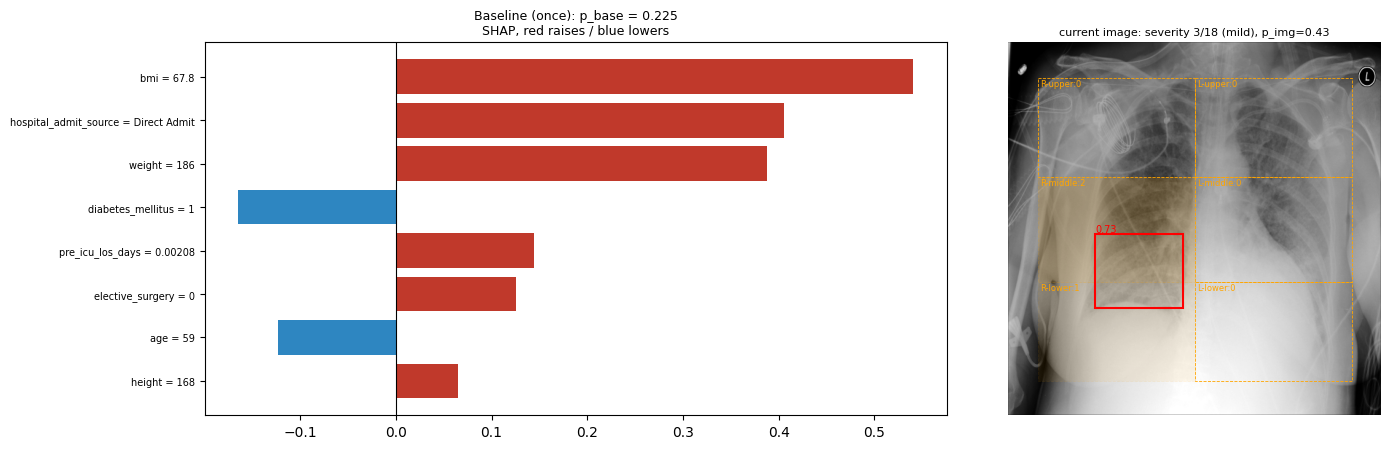

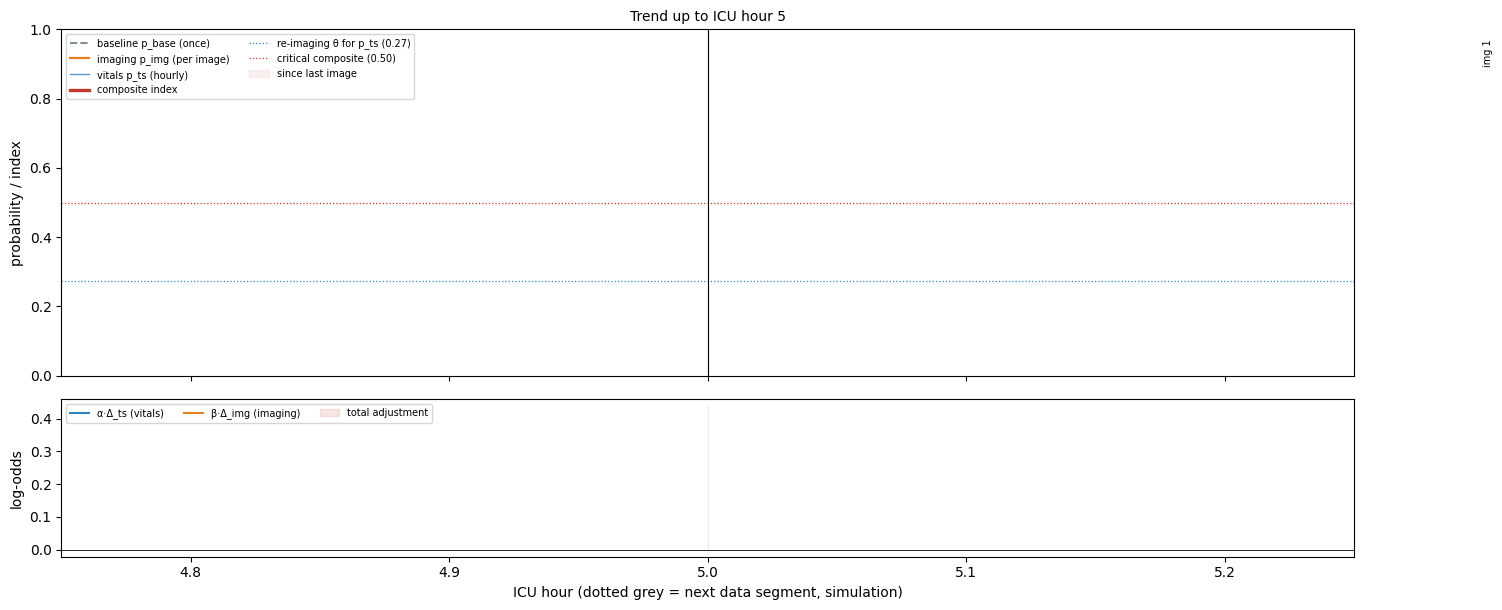

**Vitals model — variables driving the current window**

,variable,contribution,first,last,trend,n_obs
0,GCS,1.446,4.00,4.00,flat,3
1,Urine,-0.876,100.00,180.00,rising,4
2,TroponinT,0.687,0.02,0.02,,1
3,MechVent,-0.674,1.00,1.00,flat,2


**Reference notes** (other patients, MTSamples — general context only)

- *Discharge Summary — Death Summary* (similarity 0.155): “The patient was transferred to the Intensive Care Unit because of acute respiratory failure, was intubated by Critical Care, Dr. ... The patient was admitted to Intensive Care Unit and was intubated. ... Acute respiratory failure.,2. ... Acute respiratory failure, probably worsened by aspiration.,2.”

- *Surgery — Central Line Placement* (similarity 0.143): “PROCEDURE:  ,With the patient in his Intensive Care Unit bed, mechanically ventilated in the Trendelenburg position. ... Respiratory failure. ... Respiratory failure. ... INDICATIONS FOR OPERATION:  ,This 50-year-old gentleman with severe respiratory failure is mechanically ventilated.”

**Summary** (Qwen3-4B-Instruct-2507)

OVERALL STATUS: Stable ICU admission for respiratory failure; no new monitoring triggers.  
KEY DRIVERS: BMI, direct admit source, and weight raise risk; diabetes mellitus lowers risk.  
CHANGE SINCE LAST REPORT: No change in vital signs or imaging since last review.  
AGREEMENT BETWEEN MODELS: Imaging model shows mild severity; vitals and baseline models show modest risk elevation.  
CONTEXT FROM REFERENCE NOTES: Patient admitted due to acute respiratory failure, likely exacerbated by aspiration.  
LIMITATIONS: Composite index is not a mortality probability; data fused from unrelated sources; imaging based on simulated data.


✓ every number in the summary appears in the input JSON

hour  11 | p_ts 0.092 | composite 0.275 | contrib vitals -0.10 imaging +0.37 | image #1 (6 h old)
hour  17 | p_ts 0.085 | composite 0.271 | contrib vitals -0.12 imaging +0.37 | image #1 (12 h old)
hour  23 | p_ts 0.141 | composite 0.295 | contrib vitals -0.00 imaging +0.37 | image #1 (18 h old)
hour  29 | p_ts 0.094 | composite 0.276 | contrib vitals -0.09 imaging +0.37 | image #1 (24 h old)
hour  35 | p_ts 0.176 | composite 0.305 | contrib vitals +0.05 imaging +0.37 | image #1 (30 h old)
hour  41 | p_ts 0.047 | composite 0.247 | contrib vitals -0.24 imaging +0.37 | image #1 (36 h old)
hour  47 | p_ts 0.028 | composite 0.228 | contrib vitals -0.35 imaging +0.37 | image #1 (42 h old)
hour  53 | p_ts 0.064 | composite 0.259 | contrib vitals -0.18 imaging +0.37 | image #1 (48 h old)
hour  59 | p_ts 0.124 | composite 0.288 | contrib vitals -0.03 imaging +0.37 | image #1 (54 h old)
hour  65 | p_ts 0.166 | composite 0.303 | contrib vitals +0.04 imaging +0.37 | image #1 (60 h old)
hour  71 | 

In [20]:
VITALS_SHOWN = ["HR", "MAP", "NIMAP", "RespRate", "SaO2", "Temp", "GCS", "Lactate", "WBC", "Creatinine", "FiO2"]
series = p_ts_series(ts, RAW, T0, min(MAX_HOURS, len(RAW))).set_index("hour")

monitor = TriggerMonitor(TRIG, T0)
history, events, reports, alerts = [], [], [], []
assessment = im.assess(os.path.join(DEMO_IMG_DIR, f"{img0.patientId}.png"))
image_ids, last_image_hour, prev_assessment = [img0.patientId], T0, None
crit_run = imp_run = 0
stop_reason = f"reached MAX_HOURS = {MAX_HOURS}"

def make_report(hour, rtype, trigger_reason=None, prev_a=None):
    f = history[-1]["fusion"]
    prev = reports[-1] if reports else None
    ts_df = explain_long(ts, RAW, hour, top_k=4)
    q = notes_db.build_query(background["diagnosis_group"], assessment, ts_df.variable.tolist())
    notes = notes_db.retrieve(q, k=2)
    hist_df = pd.DataFrame([h["row"] for h in history])
    since = hist_df[hist_df.hour >= (prev["last_image_hour"] if prev else T0)]
    rep = {"number": len(reports) + 1, "type": rtype, "hour": hour, "trigger_reason": trigger_reason,
           "image_no": len(image_ids), "fusion": f, "alpha": ts.alpha, "beta": im.beta,
           "background": background, "source_ids": SOURCE_IDS + f" · current image RSNA {image_ids[-1][:8]}",
           "shap_df": shap_df, "shap_top": shap_top, "ts_df": ts_df, "ts_top": ts_df.to_dict("records"),
           "latest_vitals": latest_values(RAW, hour, VITALS_SHOWN),
           "image": assessment, "assessment": assessment, "last_image_hour": last_image_hour,
           "shade_from": prev["last_image_hour"] if prev else T0,
           "hours_since_prev_image": (hour - prev["last_image_hour"]) if prev else 0,
           "prev_p_ts": prev["fusion"]["p_ts"] if prev else None,
           "prev_composite": prev["fusion"]["composite"] if prev else None,
           "prev_severity": prev_a["brixia_total"] if prev_a else None,
           "severity_change": (None if prev_a is None else
                               "increased" if assessment["brixia_total"] > prev_a["brixia_total"] else
                               "decreased" if assessment["brixia_total"] < prev_a["brixia_total"] else "unchanged"),
           "since_last_image": None if prev is None else {
               "from_hour": int(since.hour.iloc[0]), "start": float(since.composite.iloc[0]),
               "end": float(since.composite.iloc[-1]), "mean": float(since.composite.mean()), "peak": float(since.composite.max())},
           "notes": notes, "fig_prefix": os.path.join(RUN_DIR, f"report{len(reports) + 1:02d}")}
    summary = build_summary(rep)
    text, src = llm.summarize(summary)
    rep.update({"summary_json": summary, "summary_text": text, "summary_source": src,
                "ungrounded": ungrounded_numbers(text, summary)})
    reports.append(rep)
    R.render(rep, hist_df, events, segments.start_hour.tolist(), im, TRIG["theta"], CRITICAL_COMPOSITE, prev_a)
    return rep

t_run = time.time()
for hour in series.index:
    p_ts = float(series.loc[hour, "p_ts"])
    trigger = monitor.step(hour, p_ts)          # never fires at T0 (cooldown starts with the first image)
    if trigger and len(image_ids) - 1 >= MAX_REIMAGINGS:
        print(f"hour {hour:3d} | trigger ({trigger}) - re-imaging limit {MAX_REIMAGINGS} reached, alert only")
        alerts.append({"hour": int(hour), "reason": trigger}); trigger = None
    if trigger:
        row, how = next_image(pool, assessment["brixia_total"], assessment["p_img"], SCENARIO, rng, exclude=image_ids)
        prev_assessment = assessment
        assessment = im.assess(os.path.join(DEMO_IMG_DIR, f"{row.patientId}.png"))
        image_ids.append(row.patientId); last_image_hour = hour
        events.append({"hour": int(hour), "image_no": len(image_ids), "reason": trigger, "rsna_id": row.patientId,
                       "selection": how, "severity": assessment["brixia_total"], "p_img": assessment["p_img"]})
    f = fuse(p_base, p_ts, assessment["p_img"], ts.alpha, im.beta, ts.base_rate, im.base_rate, CAP)
    history.append({"fusion": f, "row": {"hour": int(hour), "p_base": p_base, "p_ts": p_ts, "p_img": assessment["p_img"],
                                         "composite": f["composite"], "c_ts": f["c_ts"], "c_img": f["c_img"],
                                         "disagreement": f["disagreement"], "image_no": len(image_ids),
                                         "trigger": trigger or ""}})
    if hour == T0:
        events.append({"hour": int(hour), "image_no": 1, "reason": "initial", "rsna_id": img0.patientId,
                       "selection": f"tier {img0.tier}", "severity": assessment["brixia_total"], "p_img": assessment["p_img"]})
        make_report(hour, "initial")
    elif trigger:
        make_report(hour, "re-imaging", trigger, prev_assessment)
    elif (hour - T0) % LOG_EVERY == 0:
        print(f"hour {hour:3d} | p_ts {p_ts:.3f} | composite {f['composite']:.3f} | "
              f"contrib vitals {f['c_ts']:+.2f} imaging {f['c_img']:+.2f} | image #{len(image_ids)} ({hour - last_image_hour} h old)")

    crit_run = crit_run + 1 if f["composite"] >= CRITICAL_COMPOSITE else 0
    imp_run = imp_run + 1 if (hour >= IMPROVE_MIN_HOUR and p_ts < ts.base_rate and f["composite"] < p_base) else 0
    if crit_run >= CRITICAL_HOURS:
        stop_reason = f"critical: composite ≥ {CRITICAL_COMPOSITE} for {CRITICAL_HOURS} consecutive hours"; break
    if imp_run >= IMPROVE_HOURS:
        stop_reason = f"improving: vitals below base rate and composite below baseline for {IMPROVE_HOURS} hours"; break
print(f"\nmonitoring ended at hour {hour}: {stop_reason}  ({time.time() - t_run:.0f}s, {len(reports)} reports)")

## 6. End of monitoring — full trajectory and event log

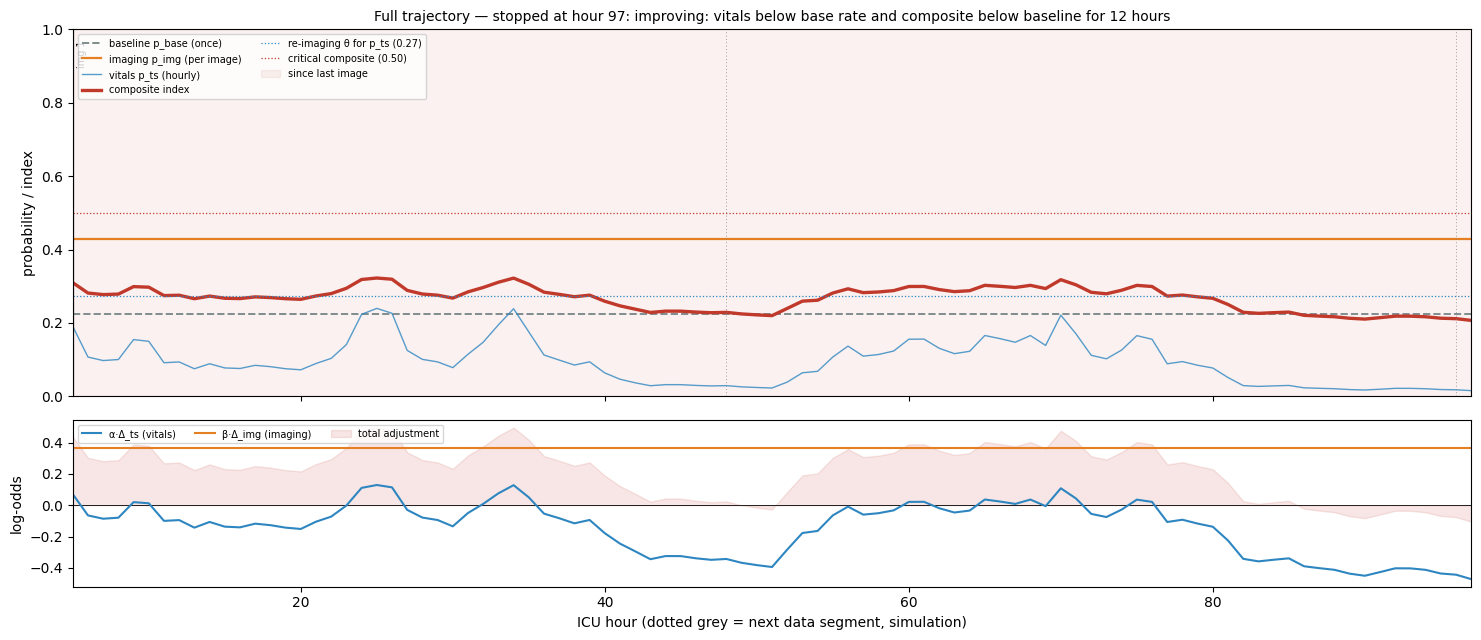

**Imaging events**

,hour,image_no,reason,rsna_id,selection,severity,p_img
0,5,1,initial,60c3a86e-4268-45f6-ae8c-003a5833287d,tier moderate,3,0.429


**Reports**

,report,hour,type,composite,p_ts,p_img,severity,summary,ungrounded numbers
0,1,5,initial,0.31,0.191,0.429,3,Qwen3-4B-Instruct-2507,0


saved to /kaggle/working/demo_run : ['full_trajectory.png', 'imaging_events.csv', 'monitoring_log.csv', 'report01_panel.png', 'report01_trend.png', 'report02_panel.png', 'report02_trend.png', 'report03_panel.png', 'report03_trend.png', 'report04_panel.png', 'report04_trend.png', 'reports.json', 'run_config.json', 'sensitivity_alpha_beta.png', 'vitals_segments.csv']


In [21]:
hist_df = pd.DataFrame([h["row"] for h in history])
fig, (a1, a2) = plt.subplots(2, 1, figsize=(15, 6.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
R.trend_chart(hist_df, events, segments.start_hour.tolist(), int(hist_df.hour.max()),
              last_image_hour, TRIG["theta"], CRITICAL_COMPOSITE, a1, a2)
a1.set_title(f"Full trajectory — stopped at hour {int(hist_df.hour.max())}: {stop_reason}", fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(RUN_DIR, "full_trajectory.png"), dpi=130); plt.show()

ev = pd.DataFrame(events)
display(Markdown("**Imaging events**")); display(ev.round(3))
display(Markdown("**Reports**"))
display(pd.DataFrame([{"report": r["number"], "hour": r["hour"], "type": r["type"], "composite": r["fusion"]["composite"],
                       "p_ts": r["fusion"]["p_ts"], "p_img": r["fusion"]["p_img"], "severity": r["image"]["brixia_total"],
                       "summary": r["summary_source"], "ungrounded numbers": len(r["ungrounded"])} for r in reports]).round(3))

hist_df.to_csv(os.path.join(RUN_DIR, "monitoring_log.csv"), index=False)
ev.to_csv(os.path.join(RUN_DIR, "imaging_events.csv"), index=False)
segments.to_csv(os.path.join(RUN_DIR, "vitals_segments.csv"), index=False)
json.dump([{"number": r["number"], "hour": r["hour"], "type": r["type"], "summary_source": r["summary_source"],
            "summary_text": r["summary_text"], "ungrounded_numbers": r["ungrounded"], "input_json": r["summary_json"]}
           for r in reports], open(os.path.join(RUN_DIR, "reports.json"), "w"), indent=2, default=str)
json.dump({"seed": SEED, "scenario": SCENARIO, "max_hours": MAX_HOURS, "cap": CAP, "critical": [CRITICAL_COMPOSITE, CRITICAL_HOURS],
           "improve": [IMPROVE_MIN_HOUR, IMPROVE_HOURS], "alpha": ts.alpha, "beta": im.beta, "trigger": TRIG,
           "stop_reason": stop_reason, "wids_encounter": int(wrow.encounter_id), "physionet_records": segments.record_id.tolist(),
           "images": image_ids, "alerts_after_limit": alerts, "llm": llm.mode}, open(os.path.join(RUN_DIR, "run_config.json"), "w"), indent=2, default=str)
print("saved to", RUN_DIR, ":", sorted(os.listdir(RUN_DIR)))

## 7. Sensitivity of the composite to α and β
The weights cannot be validated without data where all three modalities come from the same patients, so we show how the composite trajectory changes when α and β are varied (same patient, same images, same trigger events).

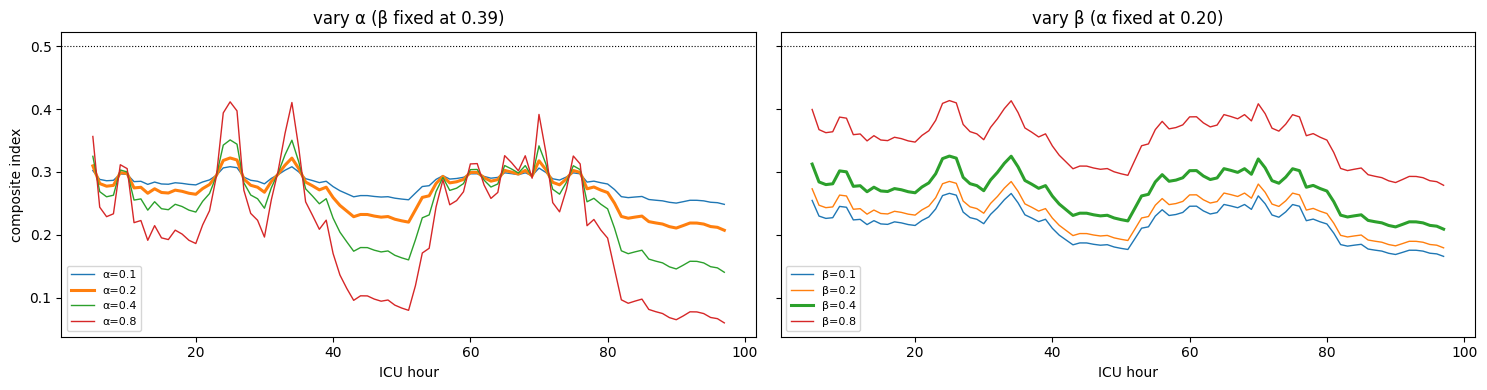

In [22]:
grid = [0.1, 0.2, 0.4, 0.8]
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for a_ in grid:
    comp = [fuse(p_base, r_.p_ts, r_.p_img, a_, im.beta, ts.base_rate, im.base_rate, CAP)["composite"] for r_ in hist_df.itertuples()]
    axes[0].plot(hist_df.hour, comp, lw=2.2 if abs(a_ - ts.alpha) < 0.05 else 1, label=f"α={a_}")
for b_ in grid:
    comp = [fuse(p_base, r_.p_ts, r_.p_img, ts.alpha, b_, ts.base_rate, im.base_rate, CAP)["composite"] for r_ in hist_df.itertuples()]
    axes[1].plot(hist_df.hour, comp, lw=2.2 if abs(b_ - im.beta) < 0.05 else 1, label=f"β={b_}")
axes[0].set(title=f"vary α (β fixed at {im.beta:.2f})", xlabel="ICU hour", ylabel="composite index")
axes[1].set(title=f"vary β (α fixed at {ts.alpha:.2f})", xlabel="ICU hour")
for ax in axes:
    ax.axhline(CRITICAL_COMPOSITE, color="k", ls=":", lw=0.8); ax.legend(fontsize=8)
    for e in events[1:]:
        ax.axvline(e["hour"], color="grey", lw=0.6)
plt.tight_layout(); plt.savefig(os.path.join(RUN_DIR, "sensitivity_alpha_beta.png"), dpi=130); plt.show()

In [23]:
shutil.make_archive(os.path.join(WORK_DIR, "demo_run"), "zip", RUN_DIR)
print("outputs:", os.path.join(WORK_DIR, "demo_run.zip"))

outputs: /kaggle/working/demo_run.zip


### Limitations to state with this demo
- The patient is a **composite of three unrelated people**; conflicts or agreements between models are artefacts of that choice.
- Beyond 48 h, vitals come from **further PhysioNet records chained end-to-end** (each matched to the previous 12 h); grey dotted lines mark the joins.
- Follow-up X-rays are **other patients' images** chosen to be more (or less) severe — this demonstrates the mechanism, not a real course.
- The composite index is a **relative index**, not a calibrated probability of death; α and β measure each model's skill on its own task.
- MedGemma only rewrites the structured JSON; the ungrounded-number check flags any number it did not receive.